In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

In [16]:
keras.utils.set_random_seed(42) ### same random star every run, so results are repeatable

PROJECT_ROOT= Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "val.csv")

##label must be numbers too: negative=0, neutral =1 , posititve =2

LABELS = ["negative","neutral", "positive"]
label_to_id = {label: i for i, label in enumerate(LABELS)}
y_train = train_df["label"].map(label_to_id).to_numpy()
y_val = val_df["label"].map(label_to_id).to_numpy()

train_texts = train_df["sentence_clean"].tolist()
val_texts = val_df["sentence_clean"].tolist()
print("Train:",len(train_texts), "| Val:", len(val_texts))
print("First 5 labels as numbers:", y_train[:5])

Train: 2456 | Val: 492
First 5 labels as numbers: [1 2 2 2 2]


In [17]:
MAX_LEN = 50 

vectorizer = keras.layers.TextVectorization(
    max_tokens = 10000,   ###keep at most 10,00 diff words
    output_sequence_length = MAX_LEN, ##pad or cut every sentence to 50
    standardize = "lower",  ##lowercase only
    split = "whitespace" ##our text is already split by spces

)

vectorizer.adapt(train_texts)  ##learn the word list from train only

vocab = vectorizer.get_vocabulary()
print("Word learned:",len(vocab))
print("First 10 IDs:", vocab[:10])

X_train = vectorizer(train_texts).numpy()
X_val = vectorizer(val_texts).numpy()
print("\nX_train shape:",X_train.shape)
print("\nSentence:", train_texts[0])
print("As IDs:",X_train[0])

Word learned: 7698
First 10 IDs: ['', '[UNK]', np.str_('the'), np.str_('.'), np.str_(','), np.str_('of'), np.str_('in'), np.str_('and'), np.str_('to'), np.str_('million')]

X_train shape: (2456, 50)

Sentence: According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .
As IDs: [ 109    8 2810    4    2   16   29  204  671    8  398  147  119    8
  161    4 2156   36   15  381    2   16   15  865    3    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


In [18]:
from sklearn.utils.class_weight import compute_class_weight

VOCAB_SIZE = len(vocab)
weights = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train)
class_weight = dict(enumerate(weights))

keras.utils.set_random_seed(42)
model = keras.Sequential([
    keras.Input(shape=(MAX_LEN,)),
    keras.layers.Embedding(input_dim=VOCAB_SIZE, output_dim=64, mask_zero=True),
    keras.layers.Bidirectional(keras.layers.LSTM(64)),   # <- two readers: forward + backward
    keras.layers.Dropout(0.3),
    keras.layers.Dense(3, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 50, 64)         │       492,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 559,107 (2.13 MB)

 Trainable params: 559,107 (2.13 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs = 30,
    batch_size=32,
    class_weight= class_weight,
    callbacks= [early_stop],
    verbose=2,
)


Epoch 1/30
77/77 - 6s - 73ms/step - accuracy: 0.4878 - loss: 0.9922 - val_accuracy: 0.7520 - val_loss: 0.7001
Epoch 2/30
77/77 - 2s - 25ms/step - accuracy: 0.8062 - loss: 0.6181 - val_accuracy: 0.7846 - val_loss: 0.5723
Epoch 3/30
77/77 - 2s - 28ms/step - accuracy: 0.9479 - loss: 0.2362 - val_accuracy: 0.7805 - val_loss: 0.6305
Epoch 4/30
77/77 - 2s - 25ms/step - accuracy: 0.9788 - loss: 0.1018 - val_accuracy: 0.7642 - val_loss: 0.8186
Epoch 5/30
77/77 - 2s - 26ms/step - accuracy: 0.9914 - loss: 0.0461 - val_accuracy: 0.8130 - val_loss: 0.7623


In [20]:
from sklearn.metrics import f1_score, classification_report

val_pred = model.predict(X_val, verbose=0).argmax(axis=1)   # pick the class with the biggest probability
print("Val Macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 3))
print(classification_report(y_val, val_pred, target_names=LABELS, digits=3))

Val Macro-F1: 0.733
              precision    recall  f1-score   support

    negative      0.679     0.633     0.655        60
     neutral      0.912     0.817     0.862       306
    positive      0.605     0.778     0.681       126

    accuracy                          0.785       492
   macro avg      0.732     0.743     0.733       492
weighted avg      0.805     0.785     0.790       492



16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


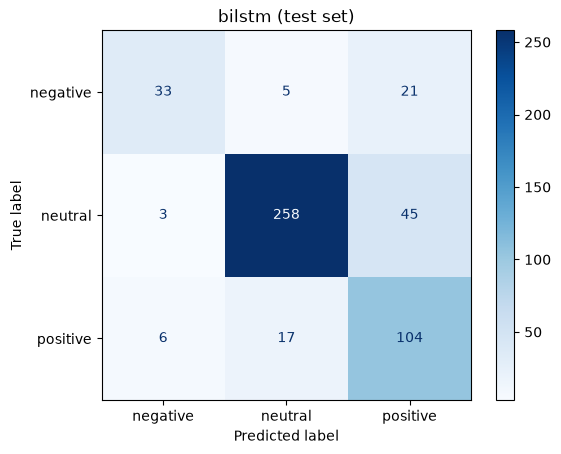

bilstm on test: accuracy 0.8028 | Macro-F1 0.7448
              precision    recall  f1-score   support

    negative      0.786     0.559     0.653        59
     neutral      0.921     0.843     0.881       306
    positive      0.612     0.819     0.700       127

    accuracy                          0.803       492
   macro avg      0.773     0.740     0.745       492
weighted avg      0.825     0.803     0.807       492

bilstm on test: accuracy 0.8028 | Macro-F1 0.7448
Saved model.


In [21]:
import sys, importlib
sys.path.append(str(PROJECT_ROOT))
import src.evaluate as ev
importlib.reload(ev)

# 1. Load the TEST set and turn it into ids with the SAME vectorizer
test_df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "test.csv")
X_test = vectorizer(test_df["sentence_clean"].tolist()).numpy()

# 2. Predict, turn ids back into words, and score ONCE
test_pred_ids = model.predict(X_test).argmax(axis=1)
test_pred = [LABELS[i] for i in test_pred_ids]
metrics = ev.evaluate(test_df["label"].tolist(), test_pred, "bilstm", PROJECT_ROOT / "results")
print("bilstm on test: accuracy", round(metrics["accuracy"], 4), "| Macro-F1", round(metrics["macro_f1"], 4))

# 3. Save the model
model.save(PROJECT_ROOT / "models" / "bilstm.keras")
print("Saved model.")